# **Source PSF Analysis | Baseline VS Mask Rotation**

In [10]:
from pathlib import Path

import numpy as np
from numpy.typing import NDArray
import matplotlib as mpl
import matplotlib.pyplot as plt

from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.mask import decode, variance
from bloodmoon.types import CoordEquatorial
import darksun as ds

from camgeom.simstudy import check_and_pick, get_source_coords

RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
plt.rcdefaults()
mpl.rcParams.update(RCPARAMS)
ds.show.set_figures_darkbkg()

In [11]:
MASK_FITS: str = "mask_NTHT_20260129_CORRECTED.fits"
SKYFIELD: str = "CameraGeometry"
DATA_FITS: str = "baseline/baseline"

ID_CAMERA: str = "cam1a"
DATASET: str = "detected"

E_min: float = 2.0  # [keV]
E_max: float = 50.0  # [keV]

UPS_X, UPS_Y = 2, 1
hide_bulk_els_y: float = 1.5   # [mm]

BASEDIR: str = "/mnt/dbb8f47e-da06-47bf-8ef5-038092af70f7/Edos_Magnificent_Manor/PhD_AASS/Coding/IROS_Data/Simulations"
# BASEDIR: str = "/mnt/d/PhD_AASS/Coding/Images_fits"
DATAPATH: str = Path(f"{BASEDIR}/{SKYFIELD}/{DATA_FITS}")


wfm: CodedMaskCamera = codedmask(f'{BASEDIR}/{MASK_FITS}', UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)

ctg = ds.get_catalogue(check_and_pick(DATAPATH, f'{ID_CAMERA}/*sources*.fits'))
sdl = ds.get_data(check_and_pick(DATAPATH, f'{ID_CAMERA}/*{DATASET}*.fits'), E_min=E_min, E_max=E_max)

In [12]:
srcID = 's8'
src_coords = get_source_coords(srcID, ctg)
phs = ds.select_source_photons(src_coords, sdl.DLdata)

CATALOG ='camera_benchmark_catalogue.fits' / Catalog file                        [astropy.io.fits.card]


Selected 182488/1379029 photons.


In [13]:
def _rot_coords_xy(c: NDArray, centre: float, angle: float) -> NDArray:
    """
    Accounts for coordinates' projection along X- and Y- tilt axis.

    Args:
        c: Array of coordinates along the x- or y-axis
        angle: Rotation angle expressed in [deg]
        centre: Coordinate of the tilt axis pivot along this axis
    
    Returns:
        Array of de-projected coordinates
    """
    angle_rad = np.deg2rad(angle)
    return (c - centre) / np.cos(angle_rad) + centre

def _rot_coords_z(
    x: NDArray,
    y: NDArray,
    centre: tuple[float, float],
    angle: float,
) -> tuple[NDArray, NDArray]:
    """
    Rotates given coordinate arrays around Z-axis, wrt (x0, y0) by specified
    angle value in [deg]. Positive angles refer to counter-clockwise rotations.

    Args:
        x: Array of coordinates along the x-axis
        y: Array of coordinates along the y-axis
        centre: Pivot rotation point for (x, y) coords
        angle: Rotation angle expressed in [deg]
    
    Returns:
        Tuple of arrays (x, y) with roto-translated coordinates
    """
    angle_rad = np.deg2rad(angle)
    cos_t, sin_t = np.cos(angle_rad), np.sin(angle_rad)

    x0, y0 = centre
    dx, dy = x - x0, y - y0
    # R @ (x - x0) + x0, but w/o creating 2D arr and broadcasting
    x_rot, y_rot = (
        cos_t * dx - sin_t * dy + x0,
        sin_t * dx + cos_t * dy + y0,
    )
    return x_rot, y_rot

def count(
    camera: CodedMaskCamera,
    data: NDArray,
    rot_angle: tuple[float, float, float] = (0.0, 0.0, 0.0),
    offset_xy: tuple[float, float] = (0.0, 0.0),
    centre: tuple[float, float] = (0.0, 0.0),
) -> tuple[NDArray, tuple[NDArray, NDArray]]:
    """
    Create 2D histogram of detector counts from event data.

    Args:
        camera: CodedMaskCamera object containing detector binning
        data: Array of event data with `X` and `Y` coordinates
        rot_angle: Rotation angles (X, Y, Z) between detector and mask plate, in [deg]
        centre: Pivot point `(x0, y0)` of the rotation along Z-axis, in [mm]
        offset_xy: Coordinate of the tilt axis pivot along (X, Y) axes, in [mm]

    Returns:
        2D array of binned detector counts
    """
    bins = [camera.bins_detector.y, camera.bins_detector.x]
    xcoords, ycoords = data["X"], data["Y"]

    # accounts for misalignments betwen coded-mask plate and detector plane
    if rot_angle[2]:  # mask rot around Z-ax --> in-plane rotation
        xcoords, ycoords = _rot_coords_z(xcoords, ycoords, centre, rot_angle[-1])
    if rot_angle[1]:  # mask rot around Y-ax --> effect on detector plane X-ax
        xcoords = _rot_coords_xy(xcoords, offset_xy[0], rot_angle[1])
    if rot_angle[0]:  # mask rot around X-ax --> effect on detector plane Y-ax
        ycoords = _rot_coords_xy(ycoords, offset_xy[1], rot_angle[0])

    counts, *_ = np.histogram2d(ycoords, xcoords, bins=bins)
    bulk_mask = (camera.bulk > 0)
    return counts * bulk_mask, bins

In [ ]:
def choose_subsample(
    x: NDArray,
    y: NDArray,
    samples_fract: float = 0.75,
) -> tuple[NDArray, NDArray]:
    """Chooses randomly a subsample for the given coords arrays."""
    n_pts = len(x)
    idxs = np.random.choice(n_pts, int(samples_fract * n_pts), replace=False)
    return x[idxs], y[idxs]

def show_coords_rotation(
    x: NDArray,
    y: NDArray,
    rot_angle: tuple[float, float, float] = (0.0, 0.0, 0.0),
    centre: tuple[float, float] = (0.0, 0.0),
    offset_xy: tuple[float, float] = (0.0, 0.0),
    edges: tuple[float, float] = None,
) -> None:
    """Shows the given coords rotation through quivers."""
    x_rot, y_rot = map(np.copy, (x, y))
    if rot_angle[2]:  # mask rot around Z-ax
        x_rot, y_rot = _rot_coords_z(x_rot, y_rot, centre, rot_angle[-1])
    if rot_angle[1]:  # mask rot around Y-ax
        x_rot = _rot_coords_xy(x_rot, offset_xy[0], rot_angle[1])
    if rot_angle[0]:  # mask rot around X-ax
        y_rot = _rot_coords_xy(y_rot, offset_xy[1], rot_angle[0])
    
    coords, rotated = map(
        lambda x, y: np.concat((x[None, :], y[None, :]), axis=0),
        (x, x_rot), (y, y_rot),
    )
    delta = rotated - coords
    plt.quiver(
        coords[0, :], coords[1, :], delta[0, :], delta[1, :],
        angles='xy', scale_units='xy', scale=1, alpha=0.6,
        color='DeepSkyBlue', width=0.002, headwidth=3, headlength=4,
    )
    if edges is not None:
        boundary_x, boundary_y = edges
        plt.xlim((-boundary_x, boundary_x))
        plt.ylim((-boundary_y, boundary_y))
    
    t = (
        f'Coords Rotation: {rot_angle} deg\n'
        f'($\\text{{C}}_{{Z}}$)={centre} mm, $\\text{{off}}_{{xy}}$={offset_xy} mm'
    )
    plt.title(t)
    plt.grid(True, linestyle='-', alpha=0.5, linewidth=0.1)
    plt.tight_layout()
    plt.show()
    return

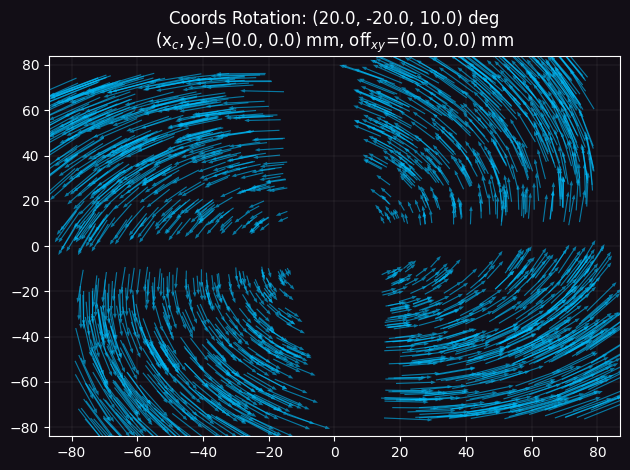

In [18]:
x_c, y_c = choose_subsample(phs['X'], phs['Y'], 0.01)

rot_kws = dict(
    rot_angle=(20.0, -20.0, 10.0),
    centre=(0.0, 0.0),
    offset_xy=(0.0, 0.0),
    edges=None,
)
show_coords_rotation(x_c, y_c, **rot_kws)

In [16]:
# mask_corr = dict(
#     rot_angle=(0.0, 0.0, 0.0),
#     centre=(0.0, 0.0),
#     offset_xy=(0.0, 0.0),
# )
# detector, _ = count(wfm, phs, **mask_corr)
# skymap = decode(wfm, detector)
# varmap = variance(wfm, detector)